In [1]:
!pip install cdsapi cfgrib eccodes cartopy --quiet

In [2]:
import xarray as xr  # netCDF library
import cartopy
import matplotlib.pyplot as plt  # plotting library

import cartopy  # Map projections library
import cartopy.crs as ccrs  # Projections list


In [3]:
import os

# Replace with your own CDS key and URL
cds_api_key = "fill in your CDS key here"
cds_url = "https://cds.climate.copernicus.eu/api"

# Write config file
os.makedirs(os.path.expanduser("~"), exist_ok=True)
with open(os.path.expanduser("~/.cdsapirc"), "w") as f:
    f.write(f"url: {cds_url}\nkey: {cds_api_key}\n")



## Data download

The data are obtained from:
https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels-monthly-means?tab=download

Even downloading the CDS data through the CDS website went very fast.

As an exercise, you can try to work with .zarr data from Google.

In [4]:
import cdsapi

dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "variable": [
        "10m_u_component_of_wind",
        "10m_v_component_of_wind"
    ],
    "year": ["2024"],
    "month": ["10"],
    "time": ["00:00"],
    "data_format": "netcdf",
    "download_format": "unarchived"
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()

2026-10-29 17:17:18,580 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-10-29 17:17:19,181 INFO Request ID is c8ca568e-0d5a-4238-8249-df9aadb2c383
INFO:ecmwf.datastores.legacy_client:Request ID is c8ca568e-0d5a-4238-8249-df9aadb2c383
2026-10-29 17:17:19,340 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successf

3e920625c45c3663faaf2a41da610f5c.nc:   0%|          | 0.00/3.76M [00:00<?, ?B/s]

'3e920625c45c3663faaf2a41da610f5c.nc'

In [5]:
## On the left under files in Google Colab, you need to copy the path
## In your case this may be different
ds = xr.open_dataset('/content/3e920625c45c3663faaf2a41da610f5c.nc')
ds

<xarray.Dataset> Size: 8MB
Dimensions:     (valid_time: 1, latitude: 721, longitude: 1440)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2024-10-01
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    u10         (valid_time, latitude, longitude) float32 4MB ...
    v10         (valid_time, latitude, longitude) float32 4MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-29T16:55 GRIB to CDM+CF via cfgrib-0.9.1...

We notice that we have to reset the longitude as per the example above as this goes from 0 to 360. We need to convert this from -180 to 180 using the following lines:

In [6]:
ds2 = ds.assign_coords(longitude=(((ds.longitude + 180) % 360) - 180))


In [7]:
ds2 = ds.sortby('longitude')
ds2


<xarray.Dataset> Size: 8MB
Dimensions:     (valid_time: 1, latitude: 721, longitude: 1440)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2024-10-01
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B ...
    expver      <U4 16B ...
Data variables:
    u10         (valid_time, latitude, longitude) float32 4MB ...
    v10         (valid_time, latitude, longitude) float32 4MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-29T16:55 GRIB to CDM+CF via cfgrib-0.9.1...

In [8]:
ds2.valid_time

<xarray.DataArray 'valid_time' (valid_time: 1)> Size: 8B
array(['2024-10-01T00:00:00.000000000'], dtype='datetime64[ns]')
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 8B 2024-10-01
    number      int64 8B ...
    expver      <U4 16B ...
Attributes:
    long_name:      time
    standard_name:  time

In [9]:
u2 = ds2.u10.sel(valid_time='2024-10-01T00:00:00.000000000')
u2

<xarray.DataArray 'u10' (latitude: 721, longitude: 1440)> Size: 4MB
[1038240 values with dtype=float32]
Coordinates:
  * latitude    (latitude) float64 6kB 90.0 89.75 89.5 ... -89.5 -89.75 -90.0
  * longitude   (longitude) float64 12kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
    number      int64 8B ...
    valid_time  datetime64[ns] 8B 2024-10-01
    expver      <U4 16B ...
Attributes: (12/32)
    GRIB_paramId:                             165
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            avgua
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               m s**-1
    long_name:                                10 metre U wind component
    units:                                    m s**-1
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [10]:
type(u2)

xarray.core.dataarray.DataArray

https://www.youtube.com/watch?v=OV12bk9ZISE


In [11]:
u2 = ds2.u10.sel(valid_time ='2024-10-01T00:00:00.000000000').load()
v2 = ds2.v10.sel(valid_time ='2024-10-01T00:00:00.000000000').load()

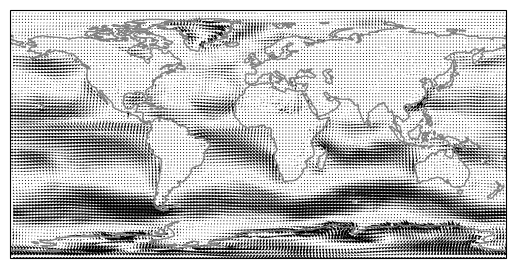

In [12]:
ax = plt.axes(projection=ccrs.PlateCarree())  # note that I changed the map projection
pu2, pv2 = u2[::9,::9], v2[::9,::9]  # we will discuss what this line does in the cells below
qv2 = ax.quiver(pu2.longitude, pu2.latitude, pu2, pv2, transform=ccrs.PlateCarree())
ax.coastlines(color='grey');

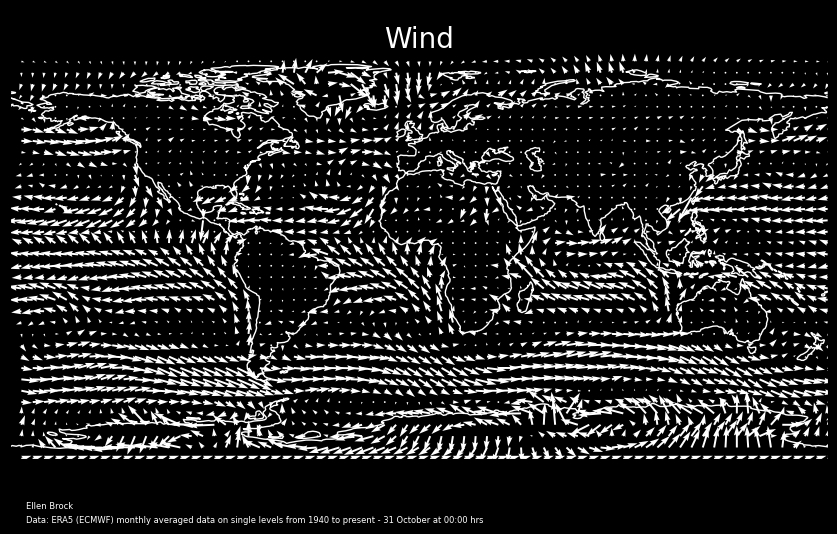

In [13]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

plt.figure(figsize=(12, 6), facecolor='black')  # black background for figure

ax = plt.axes(projection=ccrs.PlateCarree(), facecolor='black')  # black background for map

pu2, pv2 = u2[::20, ::20], v2[::20, ::20]  # sub-sample the wind vectors

# plot white arrows
qv = ax.quiver(
    pu2.longitude, pu2.latitude, pu2, pv2,
    transform=ccrs.PlateCarree(),
    color='white'
)

# draw white coastlines
ax.coastlines(color='white')

# add the title
ymin, ymax = plt.ylim()
extension = 0.1 * (ymax - ymin)
ax.set_ylim(ymin - 0.3 * extension, ymax + extension)
ax.set_title('Wind', fontsize=20, color='white', y=0.9)

# Add author and refernces
ax.text(
    0.02, -0.065,               # slightly above the data source
    "Ellen Brock",
    transform=ax.transAxes,
    fontsize=6,
    color='white',
    ha='left', va='top',
    clip_on=False,
    bbox=dict(facecolor='black', alpha=0.4, boxstyle='round,pad=0.3')
)

# Add data source
ax.text(
    0.02, -0.095,               # a bit lower (same x, smaller y)
    "Data: ERA5 (ECMWF) monthly averaged data on single levels from 1940 to present - 31 October at 00:00 hrs",
    transform=ax.transAxes,
    fontsize=6,
    color='white',
    ha='left', va='top',
    clip_on=False,
    bbox=dict(facecolor='black', alpha=0.4, boxstyle='round,pad=0.3')
)

plt.savefig(
    "wind_field_dark.png",
    dpi=300,            # high resolution
    facecolor='black',  # ensure black background is preserved
    bbox_inches='tight' # no extra whitespace
)

plt.show()


## Now it is your turn

This plot is generated using the "older way" by downloading the .nc data in CDS.

It looks like Google and [Earth Data Hub](https://earthdatahub.destine.eu/collections/era5) have created .zarr datasets for the ERA5 datasets.

Try to follow the tutorials of Project Pythia that use the .zarr data of Google and the links and some of the tutorials below (or any other tutorial). See if you can download the wind variable (or another variable) together and make a visualisation.

## References

https://fabienmaussion.info/climate_system/week_04/01_Lesson_Wind-Derivatives-Integrals.html

https://ecmwf-projects.github.io/copernicus-training-c3s/ci-windchill.html






https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-climatology.html

https://ecmwf-projects.github.io/copernicus-training-c3s/reanalysis-climatology.html